# 第11章 LunarLander：PPO で月面に着陸する

この章から、Box2D という物理シミュレーションを使った環境に進みます。**LunarLander** は、宇宙船のエンジンを噴かして、月面の旗の間（着陸パッド）にそっと着陸させる環境です。行動を「どのエンジンを噴かすか」の4つから選ぶ **離散の版** と、エンジンの強さを連続の値で決める **連続の版** があります。

この章では、第1章で CartPole に使った **PPO** を、Stable-Baselines3（SB3）で動かして楽しみます。まず離散の版を学習させて、着陸の様子を見ます。次に、PPO の仕組み（集めた経験の使い方、アドバンテージの見積もり、方策を変えすぎないためのクリップ）を、小さな NumPy のサンプルと SB3 のソースで読みます。最後に、同じ設定の PPO で連続の版も学習させ、2つの版を比べます。

- **前提**: [第10章 Pendulum](../ch10_pendulum/ch10_pendulum.ipynb)を終えていること。Actor-Critic（[第8章](../ch08_cartpole_reinforce/ch08_cartpole_reinforce.ipynb)）を読んでいると、5節が読みやすくなります
- **所要の目安**: 実行は CPU で 50 分ほど（著者の環境で、Notebook 全体を上から実行して約 46 分）
- **使う装置**: CPU で十分です（この章では GPU を使いません）

> **注記**
> - **出力の出どころ**: この Notebook に残っている出力は、著者の環境（Windows 11、CPU のみ、Gymnasium 1.3.0、Stable-Baselines3 2.9.0、PyTorch 2.14.1）で 2026-10-18 に実行したものです。各セルの出力がそのまま期待する結果で、直後の「期待する結果」の段落に読み方を書いています。学習にかかる時間は、パソコンによって変わります。
> - **進め方**: セルを上から順に実行します。サンプルのプログラムは、読んで書き写す必要はありません。動かして、読んで、数字を変えて遊んでください。

## 0. 学習目標と完了条件

この章を終えると、次のことができるようになります。

1. LunarLander の観測・2つの版の行動・報酬を説明できる
2. SB3 の PPO を RL Zoo の調整済みのハイパーパラメータで学習させ、成績と着陸の様子を見られる
3. PPO が、集めた経験を何回使い、アドバンテージをどう見積もり、方策の変化をどう抑えているかを、SB3 のソースの該当する行で示せる
4. 離散の版と連続の版の結果を、測った値で比べられる

完了条件は、この Notebook を上から最後まで実行して、4節の離散の版の PPO の **最後の時点のモデル** が、LunarLander-v3 の 100 回の評価で報酬の合計の平均 **200 以上** になることです。200 は、Gymnasium 1.3.0 に登録された LunarLander-v3 の「解けた」の目安（`reward_threshold`）です。

## 1. 全体像

この章の流れは次のとおりです。

| 節 | すること | 見るもの |
|---|---|---|
| 3節 | 環境を知る：観測・2つの版の行動・報酬 | でたらめな行動と、何もしない場合の成績 |
| 4節 | 動かして楽しむ：SB3 の PPO（離散の版） | 成績、着陸の様子 |
| 5節 | 読む：PPO の仕組み | 経験の使い方、GAE、クリップ |
| 6節 | 連続の版を PPO で学習させる | 成績、行動の分布 |
| 7節 | 比べる：離散の版と連続の版、風の中で試す | 学習中の評価、seed を変えた成績 |
| 8節 | 遊んでみる | 試してみる設定 |

PPO は、概要資料の[強化学習の手法の地図](../../overview/rl.md)で「ニューラルネットワークで近似する」領域の、**方策オン** の Actor-Critic の手法です。第8章の A2C と同じ系統で、第10章の SAC・TD3・DDPG（方策オフ）とは別の流れです。PPO は、行動の空間が `Discrete` でも `Box` でも使えるので（概要資料の [Stable-Baselines3](../../overview/sb3.md)）、この章では、同じ手法・同じ設定で2つの版を学習させます。

## 2. 準備

使うライブラリを読み込み、この章で何度も使う関数を用意します。

In [1]:
import time
from pathlib import Path

import gymnasium as gym
import imageio
import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Image
from stable_baselines3 import PPO
from stable_baselines3.common.callbacks import EvalCallback
from stable_baselines3.common.env_util import make_vec_env

torch.set_num_threads(1)  # 計算に使うスレッドを1つにする（著者が seed を変えて測ったときの条件とそろえるため）

FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)


def make_lander(continuous=False, **kwargs):
    return gym.make("LunarLander-v3", continuous=continuous, **kwargs)


# make_env() で作った環境で、方策 policy（観測 → 行動を返す関数）で episodes 回遊ばせる
# 報酬の合計の平均と標準偏差と、エピソードの終わり方の回数を返す
def evaluate(policy, episodes=100, seed=100, make_env=make_lander):
    env = make_env()
    totals = np.zeros(episodes)
    endings = {"着地して止まった": 0, "墜落・画面の外": 0, "打ち切り": 0}
    for i in range(episodes):
        observation, info = env.reset(seed=seed + i)
        while True:
            observation, reward, terminated, truncated, info = env.step(policy(observation))
            totals[i] += reward
            if terminated or truncated:
                break
        if terminated:
            endings["着地して止まった" if reward == 100 else "墜落・画面の外"] += 1
        else:
            endings["打ち切り"] += 1
    return totals.mean(), totals.std(), endings


# 方策 policy で1エピソード遊ばせ、every ステップごとの (ステップ数, 絵) の一覧を返す（絵は Gymnasium の描画）
def record_episode(policy, seed, every, continuous=False):
    env = gym.make("LunarLander-v3", continuous=continuous, render_mode="rgb_array")
    observation, info = env.reset(seed=seed)
    shots = [(0, env.render())]
    steps = 0
    while True:
        observation, reward, terminated, truncated, info = env.step(policy(observation))
        steps += 1
        if steps % every == 0 or terminated or truncated:
            shots.append((steps, env.render()))
        if terminated or truncated:
            return shots


# SB3 のモデルで、決まった行動（一番よいと見積もった行動）を選ぶ方策を返す
def sb3_policy(model):
    return lambda observation: model.predict(observation, deterministic=True)[0]

関数の説明:

- `make_lander` は、LunarLander-v3 を作ります。`continuous=True` で連続の版になります。風などの設定も `make_lander(enable_wind=True)` のように渡せます
- `evaluate` は、100 回それぞれの `reset` に `seed=100`〜`199` を渡して遊ばせます（第10章までは、最初の `reset` にだけ seed を渡していました）。報酬の合計のほかに、エピソードの終わり方（3-1節）を数えて返します
- `record_episode` と `sb3_policy` は、第10章と同じ関数です（`record_episode` には、連続の版の絵も撮れるように `continuous` を足しました）

## 3. 環境を知る：観測・2つの版の行動・報酬

### 3-1. 観測と行動の空間

**LunarLander-v3** の宇宙船は、画面の上の真ん中から、でたらめな力で押された状態で始まります。着陸パッドは、いつも座標 (0, 0) の、2本の旗の間です。燃料は無限にあります（Gymnasium 1.3.0 の `lunar_lander.py` の環境の説明）。

In [2]:
for continuous in (False, True):
    env = make_lander(continuous=continuous)
    print(f"continuous={continuous}")
    print("  観測の空間:", env.observation_space.shape, env.observation_space.dtype)
    print("  行動の空間:", env.action_space)
    env.action_space.seed(0)
    print("  でたらめな行動の例:", *[np.round(env.action_space.sample(), 3) for _ in range(3)])

continuous=False
  観測の空間: (8,) float32
  行動の空間: Discrete(4)
  でたらめな行動の例: 3 2 2
continuous=True
  観測の空間: (8,) float32
  行動の空間: Box(-1.0, 1.0, (2,), float32)
  でたらめな行動の例: [ 0.274 -0.46 ] [-0.918 -0.967] [0.627 0.826]


**期待する結果**（上の出力の読み方）: どちらの版も、観測の空間は 8 つの小数（形は `(8,)`）です。離散の版の行動の空間は `Discrete(4)` で、でたらめな行動の例は 3、2、2 のような番号です。連続の版の行動の空間は、-1.0〜1.0 の小数2つの `Box`（形は `(2,)`）で、でたらめな行動の例は [0.274 -0.46] のような、長さ2の配列です。

- 観測（8つの値）: 宇宙船の位置 x・y、速度 x・y、傾きの角度、角速度、左右の脚が地面に着いているか（着いていれば 1.0）
- 離散の版の行動（4つ）: 0 = 何もしない、1 = 左の姿勢制御エンジン、2 = 下のメインエンジン、3 = 右の姿勢制御エンジン
- 連続の版の行動（2つの値の組、どちらも -1〜1）: 1つ目はメインエンジンで、0 より大きいと噴きます（0〜1 で、出力 50%〜100%）。2つ目は左右のエンジンで、-0.5 より小さいと左、0.5 より大きいと右が噴きます（-0.5〜0.5 では噴きません）
- 報酬: 1ステップごとに、着陸パッドに近づく・遅くなる・傾きが減ると増え、遠ざかる・速くなる・傾くと減ります。脚が地面に着くと1本ごとに +10、離れると -10 です。エンジンを噴くと、メインは 1ステップ 0.3、左右は 0.03 減ります
- 終わり方: 機体が月面にぶつかる、または画面の横の外に出る（x の絶対値が 1 以上）と、-100 の報酬で終わります。機体が止まる（Box2D が「動いていない」と判断する）と、+100 の報酬で終わります。どちらも無ければ、1,000 ステップで打ち切られます（`truncated`）

報酬と終わり方は、Gymnasium 1.3.0 の `lunar_lander.py` の環境の説明と `step` の処理で確かめました。止まった場所が着陸パッドの外でも、+100 はもらえます（環境の説明にも、パッドの外に着陸できると書かれています）。パッドから遠いと、それまでの近づく・遠ざかるの報酬が小さくなります。

### 3-2. でたらめな行動と、何もしない場合で 100 回ずつ遊ぶ

In [3]:
for continuous in (False, True):
    env = make_lander(continuous=continuous)
    env.action_space.seed(0)
    do_nothing = np.zeros(2, dtype=np.float32) if continuous else 0
    for name, policy in [("でたらめな行動", lambda observation: env.action_space.sample()),
                         ("何もしない", lambda observation: do_nothing)]:
        mean, std, endings = evaluate(policy, make_env=lambda: make_lander(continuous=continuous))
        print(f"continuous={continuous}、{name}: 報酬の合計の平均 {mean:.1f}、標準偏差 {std:.1f}、{endings}")

continuous=False、でたらめな行動: 報酬の合計の平均 -179.3、標準偏差 107.7、{'着地して止まった': 0, '墜落・画面の外': 100, '打ち切り': 0}
continuous=False、何もしない: 報酬の合計の平均 -135.3、標準偏差 41.9、{'着地して止まった': 0, '墜落・画面の外': 100, '打ち切り': 0}


continuous=True、でたらめな行動: 報酬の合計の平均 -233.9、標準偏差 111.7、{'着地して止まった': 0, '墜落・画面の外': 100, '打ち切り': 0}
continuous=True、何もしない: 報酬の合計の平均 -135.3、標準偏差 41.9、{'着地して止まった': 0, '墜落・画面の外': 100, '打ち切り': 0}


**期待する結果**（上の出力の読み方）: 離散の版では、でたらめな行動の報酬の合計の平均は -179.3（標準偏差 107.7）、何もしない場合は -135.3（標準偏差 41.9）です。連続の版では、でたらめな行動が -233.9（標準偏差 111.7）、何もしない場合（行動 [0, 0]）は -135.3（標準偏差 41.9）で、離散の版の何もしない場合と同じ値です。4通りとも、100 回のすべてが「墜落・画面の外」で終わり、着地して止まった回は1回もありません。

## 4. 動かして楽しむ：SB3 の PPO（離散の版）

### 4-1. 学習させる

ハイパーパラメータは、**RL Zoo** の LunarLander-v3 用の値です（出典は末尾）。RL Zoo の値は、次の表のとおりです。書いていない設定は SB3 の既定値で、ネットワークは、方策と価値の見積もりで別々の 64 × 64 です（SB3 2.9.0 の `stable_baselines3/common/policies.py`）。

| 設定 | RL Zoo の値 | SB3 の既定値 | 意味 |
|---|---|---|---|
| `n_envs` | 16 | （1） | 同時に動かす環境の数 |
| `n_timesteps` | 1,000,000 | — | 学習のステップ数（16 個の環境の合計） |
| `n_steps` | 1024 | 2048 | 1回の更新の前に、1つの環境で集めるステップ数 |
| `batch_size` | 64 | 64 | 重みを1回動かすのに使う経験の数 |
| `n_epochs` | 4 | 10 | 集めた経験を、何周使って重みを動かすか |
| `gamma` | 0.999 | 0.99 | 割引率 |
| `gae_lambda` | 0.98 | 0.95 | GAE の λ（5-2節） |
| `ent_coef` | 0.01 | 0.0 | エントロピーの項の重み（5-4節） |

学習中の様子を見るために、`EvalCallback` で、50,000 ステップごとに 10 回遊ばせて評価し、その記録を `checkpoints` フォルダに保存します。6節の連続の版でも同じ関数を使います。著者の環境では 1,060 秒ほどかかりました。

In [4]:
# RL Zoo（v2.9.0）の PPO の LunarLander-v3 用のハイパーパラメータ（出典は末尾）。離散の版と連続の版で同じ値
PPO_PARAMS = dict(n_steps=1024, batch_size=64, gae_lambda=0.98, gamma=0.999, n_epochs=4, ent_coef=0.01)


# PPO で LunarLander を学習させ、モデルと、学習中の評価の記録（EvalCallback）を返す
def train_ppo(name, continuous, seed=0, total_timesteps=1_000_000):
    env_kwargs = dict(continuous=continuous)
    train_env = make_vec_env("LunarLander-v3", n_envs=16, seed=seed, env_kwargs=env_kwargs)
    eval_env = make_vec_env("LunarLander-v3", n_envs=1, seed=1000 + seed, env_kwargs=env_kwargs)
    # eval_freq は1つの環境のステップ数で数えるので、16 個の環境の合計で 50,000 ステップごとになるように割る
    callback = EvalCallback(eval_env, n_eval_episodes=10, eval_freq=50_000 // 16, log_path=f"checkpoints/{name}", verbose=0)
    model = PPO("MlpPolicy", train_env, seed=seed, device="cpu", tensorboard_log="logs", **PPO_PARAMS)
    start = time.perf_counter()
    model.learn(total_timesteps=total_timesteps, callback=callback, tb_log_name=name)
    print(f"学習にかかった時間: {time.perf_counter() - start:.0f} 秒")
    print("学習したステップ数:", model.num_timesteps)
    print("50,000 ステップごとの評価（10 回の平均）:", np.round(np.mean(callback.evaluations_results, axis=1), 1))
    return model, callback


disc_model, disc_callback = train_ppo("ppo_lunar_discrete", continuous=False)

学習にかかった時間: 1057 秒
学習したステップ数: 1015808
50,000 ステップごとの評価（10 回の平均）: [-127.9  -64.4 -180.1 -137.7 -191.5 -143.    30.3   60.6  157.9  203.8
  217.3  204.5  229.8  199.9  221.7  232.3  247.1  239.1  251.7  264.3]


**期待する結果**（上の出力の読み方）: 学習は著者の環境で 1057 秒でした。学習したステップ数は 1,015,808 です。50,000 ステップごとの評価（10 回の平均）は、50,000〜300,000 ステップでは -191.5〜-64.4 で、350,000 ステップで初めて正の値（30.3）になりました。そこから 400,000 ステップで 60.6、450,000 ステップで 157.9 と上がり、500,000 ステップで初めて 200 を超えました（203.8）。そのあとは、最後の 1,000,000 ステップまで 199.9〜264.3 の間にあり、一番高かったのは最後の 1,000,000 ステップの 264.3 です。

`seed=0`（学習）と `seed=1000`（学習中の評価の環境）を固定しています。`checkpoints` フォルダと `logs` フォルダは、学習のたびに作り直せるものなので、Git の管理から外しています。学習の記録を TensorBoard で見る手順は、[第1章](../ch01_first_training/ch01_first_training.ipynb)の6-2節と同じです（フォルダを `chapters\ch11_lunarlander\logs` にします）。

学習したステップ数が 1,000,000 ちょうどでないのは、PPO が「16 個の環境で 1024 ステップずつ集める」（合わせて 16,384 ステップ）ことを1回の単位にして、1,000,000 に届くまで繰り返すためです（5-1節）。

### 4-2. 成績を測る

最後の時点のモデルを、100 回評価します。

In [5]:
mean, std, endings = evaluate(sb3_policy(disc_model))
print(f"最後の時点のモデル（離散の版）: 報酬の合計の平均 {mean:.1f}、標準偏差 {std:.1f}、{endings}")

最後の時点のモデル（離散の版）: 報酬の合計の平均 263.5、標準偏差 20.7、{'着地して止まった': 100, '墜落・画面の外': 0, '打ち切り': 0}


**期待する結果**（上の出力の読み方）: 最後の時点のモデルの報酬の合計の平均は 263.5（標準偏差 20.7）で、この章の完了条件（200 以上）を満たしています。100 回すべてが「着地して止まった」で終わりました。

著者が学習の seed を 0〜4 に変えて測ったところ、最後の時点のモデルは 253.3〜266.3 で、どの seed でも完了条件の 200 以上でした。100 回のうち着地して止まった回数は 98〜100 回でした（seed ごとの値は7-1節の表）。

### 4-3. 着陸の様子を見る

最後の時点のモデルで1エピソード遊ばせ、4 ステップごとの絵を GIF に保存します。LunarLander の描画は 1 秒に 50 ステップ（`render_fps`）なので、1 枚を 80 ミリ秒で表示すると、ほぼその速さです。絵の中の赤や橙の小さな点は、エンジンを噴いたときに出る粒の描画で、Gymnasium 1.3.0 の `lunar_lander.py` では、物理の計算に影響しない飾りとされています。

エピソードのステップ数: 327


GIF の枚数: 83


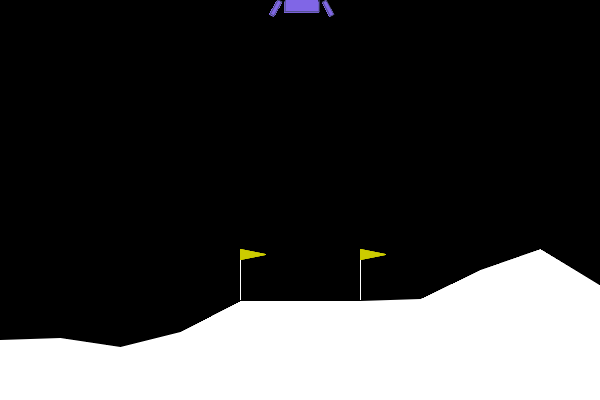

In [6]:
shots = record_episode(sb3_policy(disc_model), seed=0, every=4)
print("エピソードのステップ数:", shots[-1][0])
imageio.v3.imwrite(FIGURES / "ch11_ppo_discrete.gif", [frame for _, frame in shots], duration=80, loop=0)
print("GIF の枚数:", len(shots))
Image(filename=FIGURES / "ch11_ppo_discrete.gif")

**期待する結果**（上の出力の読み方）: このエピソードは 327 ステップで終わりました。GIF には、最初の絵と 4 ステップごとの絵 81 枚と、最後の 327 ステップ目の絵の、合わせて 83 枚を書き込みます。

**期待する結果**（VS Code などで実行した場合）: 上の出力は、4-3節の GIF です。機体は画面の上の真ん中から始まり、少し右へ流されながら下ります。そのあと、左へ戻りながらゆっくり降りて、2本の黄色い旗の間に脚を着け、そのまま止まります。

GitHub でこの Notebook を読んでいる場合、上の出力の GIF の動きは見られません（著者が、private だった 2026-10-01 に第0章で、public にした後の 2026-10-10 に第3〜5章で確かめました）。GIF は、この章のフォルダの [README.md](README.md) でも見られます。Notebook の中でも見られるように、次のセルで、同じエピソードのコマ送りの図を作ります。

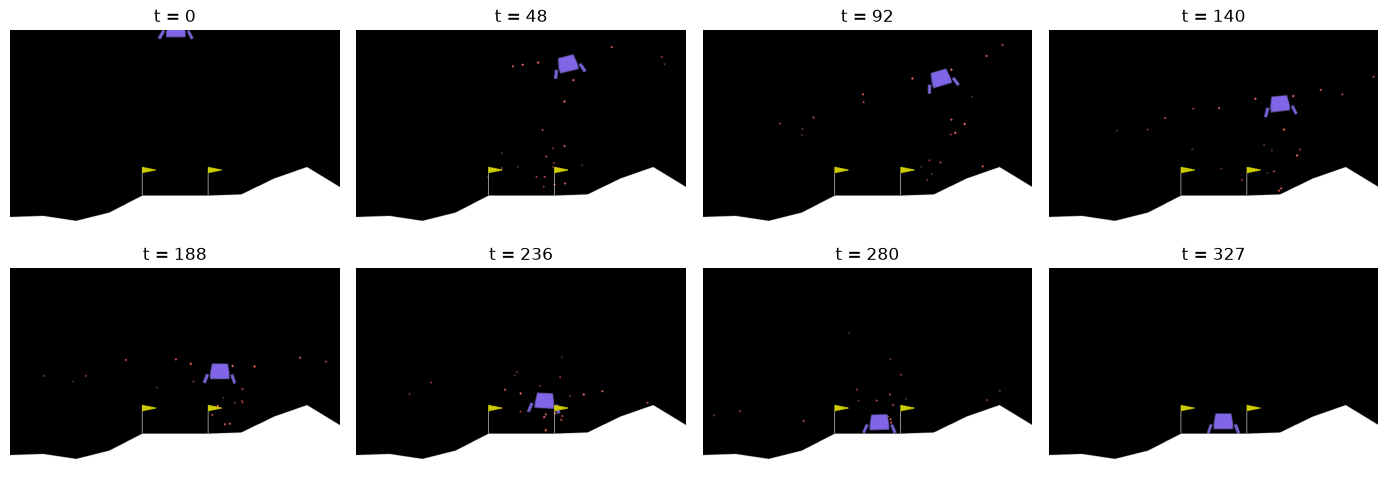

In [7]:
picks = np.linspace(0, len(shots) - 1, 8).round().astype(int)  # 等間隔に 8 枚選ぶ
fig, axes = plt.subplots(2, 4, figsize=(14, 5))
for ax, i in zip(axes.flat, picks):
    t, frame = shots[i]
    ax.imshow(frame)
    ax.set_title(f"t = {t}")
    ax.axis("off")
fig.tight_layout()
fig.savefig(FIGURES / "ch11_ppo_discrete_frames.png", dpi=80)
plt.show()

**期待する結果**（上の出力の読み方）: 4-3節のエピソードから、等間隔に選んだ 8 枚（t = 0、48、92、140、188、236、280、327）です。t = 0 では画面の上の真ん中にいた機体が、t = 48 と 92 では旗より右の上空で傾いています。t = 140 では右の旗の少し右の上空まで戻り、t = 188 と 236 で高さを下げながら旗の間に入り、t = 280 では旗の間に脚を着けています。t = 327 では、旗の間で止まっています。

## 5. 読む：PPO の仕組み

PPO（Proximal Policy Optimization）は、第8章の A2C と同じく、方策（Actor）と状態の価値の見積もり（Critic）を学ぶ方策オンの手法です。この節では、4節で学習させた `disc_model` と、SB3 2.9.0 のソースを見ながら、PPO の3つの特徴を読みます。

### 5-1. 集めた経験を、何周も使う

In [8]:
rollout = disc_model.n_envs * disc_model.n_steps
print("1回に集める経験の数:", disc_model.n_envs, "×", disc_model.n_steps, "=", rollout)
print("集めては更新した回数:", disc_model.num_timesteps // rollout)
print("1回の更新で重みを動かす回数:", disc_model.n_epochs, "周 ×", rollout // disc_model.batch_size, "個のミニバッチ =",
      disc_model.n_epochs * rollout // disc_model.batch_size)
print(disc_model.policy)

1回に集める経験の数: 16 × 1024 = 16384
集めては更新した回数: 62
1回の更新で重みを動かす回数: 4 周 × 256 個のミニバッチ = 1024
ActorCriticPolicy(
  (features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (pi_features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (vf_features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (mlp_extractor): MlpExtractor(
    (policy_net): Sequential(
      (0): Linear(in_features=8, out_features=64, bias=True)
      (1): Tanh()
      (2): Linear(in_features=64, out_features=64, bias=True)
      (3): Tanh()
    )
    (value_net): Sequential(
      (0): Linear(in_features=8, out_features=64, bias=True)
      (1): Tanh()
      (2): Linear(in_features=64, out_features=64, bias=True)
      (3): Tanh()
    )
  )
  (action_net): Linear(in_features=64, out_features=4, bias=True)
  (value_net): Linear(in_features=64, out_features=1, bias=True)
)


**期待する結果**（上の出力の読み方）: 1回に集める経験の数は、16 個の環境 × 1024 ステップ = 16,384 です。集めては更新した回数は 62 回で、16,384 × 62 = 1,015,808 は、4-1節の学習したステップ数と同じです。1回の更新では、4 周 × 256 個のミニバッチで、重みを 1,024 回動かしています。最後の表示は方策のネットワークの形で、`policy_net` と `value_net` が、どちらも 8 → 64 → 64（間に `Tanh`）の層です。`action_net` は 64 → 4、最後の `value_net` は 64 → 1 です。

PPO の学習は、次の繰り返しです（SB3 2.9.0 の `stable_baselines3/common/on_policy_algorithm.py` の `learn` と、`stable_baselines3/ppo/ppo.py` の `train`）。

1. 今の方策で、16 個の環境を 1024 ステップずつ動かして、経験を集める（`collect_rollouts`）
2. 集めた経験から、ステップごとのアドバンテージ（その行動が、平均よりどれだけよかったか）を見積もる（5-2節）
3. 集めた経験を、64 個ずつのミニバッチに分けて重みを動かす。これを、経験を混ぜ直しながら 4 周繰り返す（5-3節・5-4節）
4. 集めた経験を捨てて、1 に戻る

方策オンの手法は、今の方策で集めた経験で、今の方策を学びます。第8章の A2C は、集めた経験で重みを1回動かしたら、その経験を捨てていました。PPO は、同じ経験で何回も重みを動かすので、経験を無駄なく使えます。ただし、重みを動かすほど、方策は経験を集めたときの方策から離れていきます。離れすぎないように抑えるのが、5-3節のクリップです。

上の出力の最後は、方策のネットワークの形です。`policy_net` と `value_net`（`mlp_extractor` の中）が、方策と価値の見積もりの、別々の 64 × 64 の層です。最後の `action_net` が 4 つの行動の点数を出し、`value_net` が状態の価値を1つ出します。

### 5-2. アドバンテージの見積もり（GAE）

PPO は、アドバンテージを **GAE**（Generalized Advantage Estimation）で見積もります。SB3 では、`stable_baselines3/common/buffers.py` の `compute_returns_and_advantage` が、集めた経験を後ろから順にたどって計算します。次のセルは、その計算を、1つの環境・1つのエピソードの場合に絞って NumPy で書いたものです。

In [9]:
# GAE：rewards はステップごとの報酬、values は Critic が見積もった状態の価値（エピソードは最後のステップで終わるとする）
def gae(rewards, values, gamma, lam):
    advantages = np.zeros(len(rewards))
    last = 0.0
    for t in reversed(range(len(rewards))):
        next_value = values[t + 1] if t + 1 < len(rewards) else 0.0  # 終わった後の価値は 0
        delta = rewards[t] + gamma * next_value - values[t]  # 1ステップ分の TD 誤差
        last = delta + gamma * lam * last  # 後ろのステップの TD 誤差を、(γλ) 倍ずつ足し込む
        advantages[t] = last
    return advantages


rewards = np.array([0.0, 0.0, 0.0, 0.0, 100.0])  # 最後のステップで +100 をもらう
values = np.array([10.0, 20.0, 40.0, 60.0, 80.0])  # Critic の見積もり（例として決めた値）
for lam in (0.0, 0.98, 1.0):
    print(f"λ = {lam}: アドバンテージ", np.round(gae(rewards, values, gamma=0.999, lam=lam), 1))

λ = 0.0: アドバンテージ [10.  20.  19.9 19.9 20. ]
λ = 0.98: アドバンテージ [85.7 77.3 58.6 39.5 20. ]
λ = 1.0: アドバンテージ [89.6 79.7 59.8 39.9 20. ]


**期待する結果**（上の出力の読み方）: λ = 0 のアドバンテージは [10.0, 20.0, 19.9, 19.9, 20.0] で、どのステップも 1ステップ分の TD 誤差です。λ = 1 では [89.6, 79.7, 59.8, 39.9, 20.0] で、前のステップほど大きくなります。たとえば最初のステップは、最後の +100 を割り引いた値（約 99.6）から、Critic の見積もり 10 を引いた値です。λ = 0.98 は [85.7, 77.3, 58.6, 39.5, 20.0] で、λ = 1 に近い値です。最後のステップは、どの λ でも 20.0（報酬 100 − 見積もり 80）です。

- `delta` は、1ステップ分の TD 誤差（「報酬 + γ × 次の状態の価値」と「今の状態の価値」の差）です。λ = 0 では、アドバンテージは TD 誤差そのものになります。Critic の見積もりに頼るので、ばらつきは小さいですが、Critic がずれているとアドバンテージもずれます
- λ = 1 では、アドバンテージは「その先の報酬を実際に割り引いて足したもの − 今の状態の価値」になります（第8章の REINFORCE に、価値の見積もりを引いた形）。Critic のずれの影響は受けませんが、その先のすべての報酬のばらつきを受けます
- λ を 0〜1 の間にすると、その間をとります。RL Zoo の値は λ = 0.98 です

SB3 の計算は、このセルと同じ形で、16 個の環境をまとめて計算します。このセルとの違いは、次のとおりです。

- 集めた経験の最後のステップで、エピソードがまだ続いているときは、その先の価値を Critic の見積もり（`last_values`）で補います（`buffers.py` の `compute_returns_and_advantage`）
- 集めた経験の途中でエピソードが終わったところでは、その先の TD 誤差を足し込みません（同じ関数の `next_non_terminal`）
- 1,000 ステップで打ち切られた（`truncated`）ステップでは、打ち切られた先の価値を Critic で見積もり、γ 倍して報酬に足します（`on_policy_algorithm.py` の `collect_rollouts`）

PPO の学習に使う価値の目標（`returns`）は、アドバンテージ + 今の状態の価値です（`buffers.py` の `self.returns = self.advantages + self.values`）。

### 5-3. 方策を変えすぎないためのクリップ

PPO の方策の損失は、ステップごとに、**確率の比**（今の方策がその行動を選ぶ確率 ÷ 経験を集めたときの方策の確率）を使って計算します。SB3 の `ppo.py` の `train` の、次の行です。

```python
ratio = th.exp(log_prob - rollout_data.old_log_prob)
policy_loss_1 = advantages * ratio
policy_loss_2 = advantages * th.clamp(ratio, 1 - clip_range, 1 + clip_range)
policy_loss = -th.min(policy_loss_1, policy_loss_2).mean()
```

`clip_range` は、SB3 の既定値の 0.2 です（RL Zoo の値でも変えていません）。次のセルで、アドバンテージが +1 と -1 のときに、比を変えると目的（`th.min(...)` の値。これを大きくする向きに重みを動かします）がどう変わるかを計算します。

比           [0.5 0.8 1.  1.2 1.5]
A = +1 の目的  [0.5 0.8 1.  1.2 1.2]
A = -1 の目的  [-0.8 -0.8 -1.  -1.2 -1.5]


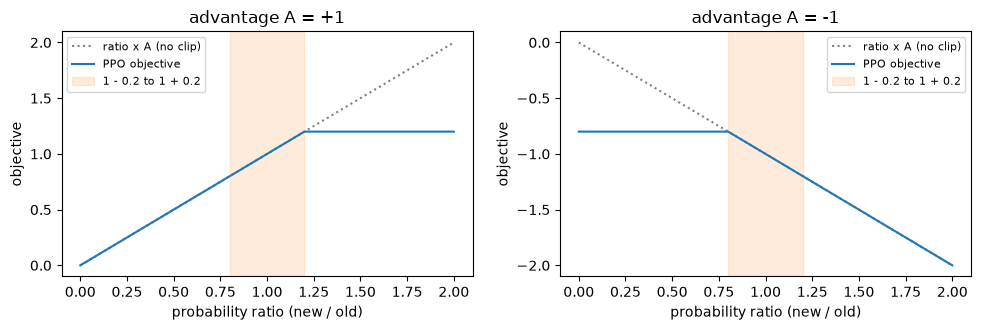

In [10]:
# PPO のクリップした目的：比 ratio とアドバンテージ advantage から、min(比 × A, clip(比) × A) を計算する
def clipped_objective(ratio, advantage, clip_range=0.2):
    return np.minimum(ratio * advantage, np.clip(ratio, 1 - clip_range, 1 + clip_range) * advantage)


ratios = np.array([0.5, 0.8, 1.0, 1.2, 1.5])
print("比          ", ratios)
for advantage in (1.0, -1.0):
    print(f"A = {advantage:+.0f} の目的 ", clipped_objective(ratios, advantage))

r = np.linspace(0, 2, 201)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=False)
for ax, advantage in zip(axes, (1.0, -1.0)):
    ax.plot(r, r * advantage, ":", color="gray", label="ratio x A (no clip)")
    ax.plot(r, clipped_objective(r, advantage), color="tab:blue", label="PPO objective")
    ax.axvspan(0.8, 1.2, color="tab:orange", alpha=0.15, label="1 - 0.2 to 1 + 0.2")
    ax.set_xlabel("probability ratio (new / old)")
    ax.set_ylabel("objective")
    ax.set_title(f"advantage A = {advantage:+.0f}")
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "ch11_clip.png", dpi=80)
plt.show()

**期待する結果**（上の出力の読み方）: アドバンテージが +1 のとき、目的は比 0.5〜1.2 では比と同じ値ですが、比 1.5 では 1.2 で止まっています。アドバンテージが -1 のとき、比 0.8〜1.5 では比 × (-1) と同じ値ですが、比 0.5 では -0.8 で止まっています。図では、青い線（PPO の目的）が、A = +1 では比 1.2 より右で、A = -1 では比 0.8 より左で、横一直線になっています。灰色の点線（クリップしない比 × A）と青い線は、それ以外の範囲で重なっています。

- アドバンテージが正（平均よりよかった行動）なら、目的を大きくするには、その行動の確率を上げます（比を大きくします）。ただし、比が 1.2 を超えると目的が増えなくなるので、それ以上確率を上げても得をしません
- アドバンテージが負（平均より悪かった行動）なら、確率を下げます（比を小さくします）。比が 0.8 を下回ると、目的が増えなくなります
- 反対の向き（よかった行動の確率が下がった、悪かった行動の確率が上がった）には、クリップは効きません。`min` で小さいほうをとるので、方策が悪い向きにずれたぶんは、そのまま目的に表れます

目的が増えなくなった範囲では、その経験から重みを動かす力（勾配）が 0 になります。こうして、同じ経験で 4 周重みを動かしても、比が 0.8〜1.2 の範囲の外に出た経験からは、それ以上その向きに動かさないようにしています（範囲の外に出ること自体を禁じるわけではありません）。SB3 は、比が範囲の外に出た経験の割合を `clip_fraction` として記録し、TensorBoard の `train/clip_fraction` で見られます。

### 5-4. 損失の合計とエントロピー

```python
loss = policy_loss + self.ent_coef * entropy_loss + self.vf_coef * value_loss
```

SB3 の `ppo.py` は、方策の損失（5-3節）、エントロピーの損失、価値の損失を1つに足して、方策と価値の見積もりの重みを一緒に動かします。

- `value_loss` は、Critic の見積もりと、5-2節の `returns` のずれの2乗の平均です。重み `vf_coef` は SB3 の既定値の 0.5 です
- `entropy_loss` は、方策のエントロピー（行動の選び方のばらつき）の符号を逆にしたものです。RL Zoo の値は `ent_coef=0.01` で、行動の選び方を早く1つに決めてしまわないように、ばらつきを少し保つ向きに働きます（SB3 の既定値は 0.0）
- アドバンテージは、ミニバッチごとに平均 0・標準偏差 1 にそろえてから使います（`normalize_advantage=True`、SB3 の既定値）。第8章の「収益の標準化」と同じ考え方です

## 6. 連続の版を PPO で学習させる

### 6-1. 学習させる

同じ `train_ppo` で、`continuous=True` にして学習させます。ハイパーパラメータは、RL Zoo の LunarLanderContinuous-v3 用の値で、離散の版とすべて同じです（`LunarLanderContinuous-v3` は、`LunarLander-v3` に `continuous=True` を渡したものとして登録されています。Gymnasium 1.3.0 の `gymnasium/envs/__init__.py`）。著者の環境では 1,600 秒ほどかかりました。

In [11]:
cont_model, cont_callback = train_ppo("ppo_lunar_continuous", continuous=True)
mean, std, endings = evaluate(sb3_policy(cont_model), make_env=lambda: make_lander(continuous=True))
print(f"最後の時点のモデル（連続の版）: 報酬の合計の平均 {mean:.1f}、標準偏差 {std:.1f}、{endings}")

学習にかかった時間: 1593 秒
学習したステップ数: 1015808
50,000 ステップごとの評価（10 回の平均）: [-118.   -69.6 -116.7   -7.5   50.7  171.1  135.2  186.3  192.7  207.7
  141.2  212.7  208.9  231.1  234.1  227.8  205.3  233.5  235.7  248.8]


最後の時点のモデル（連続の版）: 報酬の合計の平均 256.3、標準偏差 45.9、{'着地して止まった': 97, '墜落・画面の外': 3, '打ち切り': 0}


**期待する結果**（上の出力の読み方）: 学習は著者の環境で 1593 秒でした。50,000 ステップごとの評価（10 回の平均）は、50,000〜150,000 ステップでは -118.0〜-69.6 で、250,000 ステップで初めて正の値（50.7）になり、300,000 ステップで 171.1 に上がりました。初めて 200 を超えたのは 500,000 ステップ（207.7）で、そのあとは 141.2〜248.8 の間にあります。最後の時点のモデルの報酬の合計の平均は 256.3（標準偏差 45.9）で、100 回のうち 97 回が「着地して止まった」、3 回が「墜落・画面の外」で終わりました。

著者が学習の seed を 0〜4 に変えて測ったところ、連続の版の最後の時点のモデルは 221.9〜275.8 で、どの seed でも 200 以上でした。100 回のうち着地して止まった回数は 83〜100 回でした（seed ごとの値は7-1節の表）。

### 6-2. 方策が出す分布を見る

PPO の方策は、行動そのものではなく、**行動の確率の分布** を出します。学習中は、その分布から行動を選んで探索し、評価や GIF では `deterministic=True` で、一番確率の高い行動（連続の版では分布の真ん中の値）を選びました。同じ観測（`seed=0` で始めたときの最初の観測）で、2つのモデルが出す分布を見ます。

In [12]:
observation, info = make_lander().reset(seed=0)
with torch.no_grad():
    disc_dist = disc_model.policy.get_distribution(disc_model.policy.obs_to_tensor(observation)[0]).distribution
    cont_dist = cont_model.policy.get_distribution(cont_model.policy.obs_to_tensor(observation)[0]).distribution
print("離散の版: 4つの行動の確率", np.round(disc_dist.probs.numpy()[0], 3))
print("連続の版: 正規分布の平均", np.round(cont_dist.mean.numpy()[0], 3), "、標準偏差", np.round(cont_dist.stddev.numpy()[0], 3))

離散の版: 4つの行動の確率 [0.002 0.057 0.941 0.   ]
連続の版: 正規分布の平均 [ 1.165 -1.657] 、標準偏差 [0.844 0.978]


**期待する結果**（上の出力の読み方）: 離散の版の方策は、この観測で、行動 2（メインエンジン）を 0.941 の確率で選び、行動 1（左のエンジン）は 0.057、行動 0（何もしない）は 0.002 です。行動 3（右のエンジン）は、小数第3位で丸めると 0 です（表示は `0.`）。連続の版の方策は、正規分布の平均が [1.165, -1.657]、標準偏差が [0.844, 0.978] です。平均は、どちらも -1〜1 の外にあります。

- 離散の版の方策は、4つの行動の確率を出します（SB3 の `stable_baselines3/common/distributions.py` の `CategoricalDistribution`）
- 連続の版の方策は、2つの値それぞれの正規分布の平均と標準偏差を出します（同じファイルの `DiagGaussianDistribution`）。平均は観測からネットワークで計算し、標準偏差は観測によらない重み（`log_std`）で、学習の始めは 1.0 です（`log_std_init=0.0` が既定値）。学習が進むと、この標準偏差も、損失を小さくする向きに変わります（6-2節の出力では 0.844 と 0.978）
- 正規分布から選んだ値は、-1〜1 の外に出ることがあります。SB3 は、環境に渡す前に、行動の空間の範囲に切り詰めます（`on_policy_algorithm.py` の `collect_rollouts` と、`policies.py` の `predict` の `np.clip`）。6-2節の出力の平均 [1.165, -1.657] なら、`deterministic=True` で選ぶ行動は [1, -1] に切り詰められ、メインエンジンは出力 100%、左右のエンジンは左が出力 100% で噴きます

## 7. 比べる：離散の版と連続の版

### 7-1. 学習中の評価と、seed を変えた成績

4節と6節の、学習中の評価（10 回の平均）を並べます。

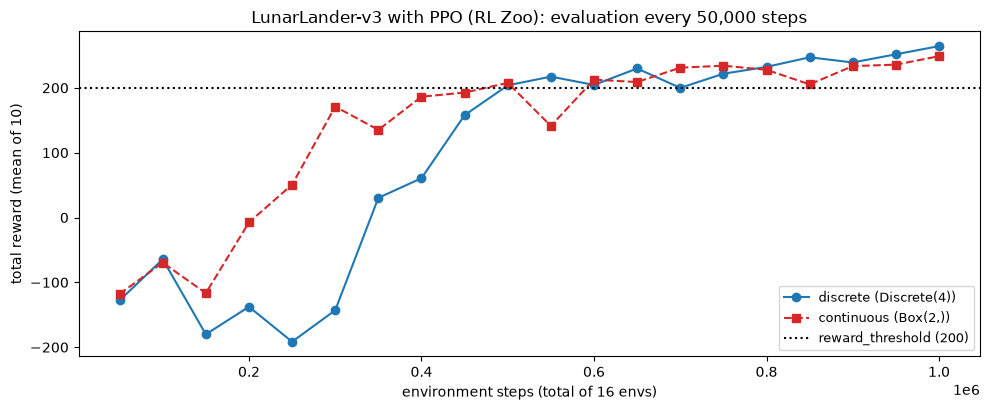

In [13]:
fig, ax = plt.subplots(figsize=(10, 4.2))
for callback, style, color, label in [(disc_callback, "o-", "tab:blue", "discrete (Discrete(4))"),
                                      (cont_callback, "s--", "tab:red", "continuous (Box(2,))")]:
    ax.plot(callback.evaluations_timesteps, np.mean(callback.evaluations_results, axis=1), style, color=color, label=label)
ax.axhline(200, color="black", linestyle=":", label="reward_threshold (200)")
ax.set_xlabel("environment steps (total of 16 envs)")
ax.set_ylabel("total reward (mean of 10)")
ax.set_title("LunarLander-v3 with PPO (RL Zoo): evaluation every 50,000 steps")
ax.legend(loc="lower right", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES / "ch11_learning_curve.png", dpi=80)
plt.show()

**期待する結果**（上の出力の読み方）: 青い丸の実線が離散の版（4節）、赤い四角の破線が連続の版（6節）の、50,000 ステップごとの評価です。黒い点線が、Gymnasium の「解けた」の目安の 200 です。赤い四角は 150,000 ステップ（-116.7）を底に上がり、300,000 ステップで 171.1 になりました。青い丸は 300,000 ステップまで -200〜-60 ほどの間を上下し、350,000 ステップで 30.3 に上がりました。どちらも初めて 200 を超えたのは 500,000 ステップで、そのあとは2本とも、ほぼ 200〜265 の間にあります（連続の版の 550,000 ステップの 141.2 を除きます）。

著者が学習の seed を 0〜4 に変えて測った値を並べます（評価はこの Notebook の `evaluate` と同じ 100 回、最後の時点のモデル）。

| 学習の seed | 離散の版（着地して止まった回数） | 連続の版（着地して止まった回数） |
|---|---|---|
| 0（この Notebook） | 263.5（100 回） | 256.3（97 回） |
| 1 | 266.3（99 回） | 275.8（99 回） |
| 2 | 263.8（100 回） | 259.4（94 回） |
| 3 | 253.3（98 回） | 221.9（83 回） |
| 4 | 256.1（100 回） | 262.8（100 回） |

どちらの版も、どの seed でも 200 以上でした。離散の版は 253.3〜266.3 の狭い範囲に入り、連続の版は 221.9〜275.8 と、seed による違いが大きくなりました。学習中の評価が初めて 200 以上になったステップ数は、記録の残っている seed で、離散の版が 500,000〜650,000（seed 0・3・4）、連続の版が 300,000〜500,000（seed 0・2・3・4）でした。この Notebook の実行では、学習の時間は離散の版が 1057 秒、連続の版が 1593 秒でした（差の原因は確かめていません）。

### 7-2. 風の中で試す

LunarLander には、宇宙船に横風と回転の乱れを加える設定（`enable_wind=True`）があります。風の強さの既定値は `wind_power=15.0`、`turbulence_power=1.5` です（Gymnasium 1.3.0 の `lunar_lander.py`）。風の無い環境で学習した2つのモデルを、風のある環境で 100 回評価します。

In [14]:
for name, model, continuous in [("離散の版", disc_model, False), ("連続の版", cont_model, True)]:
    mean, std, endings = evaluate(sb3_policy(model), make_env=lambda: make_lander(continuous=continuous, enable_wind=True))
    print(f"{name}（風あり）: 報酬の合計の平均 {mean:.1f}、標準偏差 {std:.1f}、{endings}")

離散の版（風あり）: 報酬の合計の平均 132.2、標準偏差 125.5、{'着地して止まった': 56, '墜落・画面の外': 43, '打ち切り': 1}


連続の版（風あり）: 報酬の合計の平均 169.9、標準偏差 118.9、{'着地して止まった': 73, '墜落・画面の外': 27, '打ち切り': 0}


**期待する結果**（上の出力の読み方）: 風のある環境では、離散の版は平均 132.2（標準偏差 125.5）で、100 回のうち 56 回が「着地して止まった」、43 回が「墜落・画面の外」、1 回が「打ち切り」でした。連続の版は平均 169.9（標準偏差 118.9）で、73 回が「着地して止まった」、27 回が「墜落・画面の外」でした。どちらも、風の無い環境での成績（4-2節の 263.5、6-1節の 256.3）より低く、平均は 200 に届いていません。

## 8. 遊んでみる

**やってみよう**:

- 7-2節のセルの `make_lander(continuous=continuous, enable_wind=True)` に、`wind_power=5.0` のように風の強さ（既定は 15.0。0〜20 が推奨の範囲）を渡してみてください。7-2節の値は、seed 0 で学習した2つのモデルを1つずつ測ったもので、著者は seed を変えて測っていません
- 4-1節の `train_ppo` の `env_kwargs = dict(continuous=continuous)` を `dict(continuous=continuous, enable_wind=True)` に変えて、風のある環境で学習させてみてください（著者は確かめていません）
- 4-1節の `PPO_PARAMS` に `clip_range=0.1` や `clip_range=0.4` を足して、クリップの幅を変えてみてください（SB3 の既定値は 0.2。著者は確かめていません）
- 5-2節のセルの `rewards` や `values` を変えて、λ ごとのアドバンテージの違いを見てみてください
- 4-1節の `train_ppo(...)` に `total_timesteps=500_000` を渡して、学習を半分にしてみてください。7-1節の図では、seed 0 の学習中の評価は 500,000 ステップで 200 を超えていますが、その時点のモデルを 100 回評価した値は、著者は確かめていません

## 9. まとめ

この章では、LunarLander を PPO で解きました。

| したこと | 使ったもの | 節 |
|---|---|---|
| 観測・2つの版の行動・報酬を確かめ、でたらめな行動で遊ぶ | `continuous`、`env.action_space` | 3節 |
| SB3 の PPO を RL Zoo の値で学習させる（離散の版） | `PPO`、`make_vec_env`、`EvalCallback` | 4節 |
| PPO の経験の使い方・GAE・クリップを読む | `gae()`、`clipped_objective()`、SB3 の `ppo.py` | 5節 |
| 同じ設定で連続の版を学習させ、方策が出す分布を見る | `continuous=True`、`get_distribution` | 6節 |
| 2つの版を比べ、風の中で試す | seed 0〜4 の値、`enable_wind` | 7節 |

LunarLander では、でたらめな行動でも、何もしない場合でも、100 回とも墜落しました。SB3 の PPO は、RL Zoo の調整済みの値で 1,000,000 ステップ学習させると、離散の版でも連続の版でも、seed 0〜4 のどれでも、最後の時点のモデルが「解けた」の目安の 200 を超えました。PPO は、16 個の環境で集めた 16,384 ステップの経験を 4 周使って重みを動かし、アドバンテージを GAE で見積もり、確率の比を 0.8〜1.2 でクリップして、方策を一度に変えすぎないようにします。離散の版と連続の版の違いは、方策が出す分布（4つの行動の確率か、2つの値の正規分布か）で、ハイパーパラメータは同じ値でした。風の無い環境で学習したモデルは、風のある環境では、seed 0 のモデルで、どちらの版も平均が 200 を下回りました。

- 次に読むもの: [第12章 BipedalWalker](../ch12_bipedalwalker/ch12_bipedalwalker.ipynb)
- 手法の位置づけを見直したいときは、概要資料の[強化学習](../../overview/rl.md)に戻ってください

## 出典

この章は、次の文献・公式の文書と、導入した Gymnasium 1.3.0・Stable-Baselines3 2.9.0 のソースと動作（2026-10-17・18 確認）をもとに、著者の言葉でまとめたものです。逐語の転載ではありません。5節の NumPy のサンプルのコードは著者が書いたもので、5節のコードの引用は Stable-Baselines3（MIT License）の `ppo.py` の該当する行です。

- J. Schulman, F. Wolski, P. Dhariwal, A. Radford, O. Klimov, "Proximal policy optimization algorithms", arXiv:1707.06347, 2017（PPO）
- J. Schulman, P. Moritz, S. Levine, M. Jordan, P. Abbeel, "High-dimensional continuous control using generalized advantage estimation", *International Conference on Learning Representations (ICLR)*, 2016（GAE）
- RL Baselines3 Zoo, v2.9.0 の `hyperparams/ppo.yml`（LunarLander-v3・LunarLanderContinuous-v3 のハイパーパラメータ）: https://github.com/DLR-RM/rl-baselines3-zoo/blob/v2.9.0/hyperparams/ppo.yml
- Stable-Baselines3 のソース（v2.9.0。`stable_baselines3/ppo/ppo.py`・`stable_baselines3/common/on_policy_algorithm.py`・`stable_baselines3/common/buffers.py`・`stable_baselines3/common/distributions.py`・`stable_baselines3/common/policies.py`）: https://github.com/DLR-RM/stable-baselines3/tree/v2.9.0/stable_baselines3
- Gymnasium 1.3.0 のソース（導入したパッケージの中の `gymnasium/envs/box2d/lunar_lander.py` の環境の説明と `step` の処理、`gymnasium/envs/__init__.py` の登録）

4節の GIF とコマ送りの図の絵は、Gymnasium（MIT License）の LunarLander の描画処理が出力したものです（`lunar_lander.py` の作者の表記は Oleg Klimov。描画は pygame で図形を描く処理で、画像の素材は使っていません）。グラフは、著者が matplotlib で描いたものです。この教科書のライセンスと、使っている第三者のソフトウェアの一覧は、リポジトリの [LICENSE.md](../../LICENSE.md) にあります。